# Detector-Level PDFs

EOS can convolve a truth-level probability density function (PDF) with a detector resolution
function to obtain a *detector-level* PDF, using [eos.DetectorLevelPDF](../reference/python.rst#eos.DetectorLevelPDF).
The convolution is carried out numerically, via a multi-dimensional discrete Fourier transform, and
its result is itself a [SignalPDF](../reference/python.rst#eos.SignalPDF): it can be evaluated,
sampled, and plotted like any other PDF.

This notebook illustrates the full pipeline for the decay $\bar{B}^0\to D^+\mu^-\bar\nu$:

1. we build the truth-level 2D PDF in $q^2$ and $\cos\theta_\ell$, sample it, and check that the
   $q^2$ marginal of the samples agrees with the built-in 1D PDF;
2. we build a Gaussian detector resolution in $q^2$ (with no smearing in $\cos\theta_\ell$) from
   EOS expressions, and combine it with the truth-level PDF into a detector-level PDF;
3. we validate the convolution by comparing a histogram of the step-1 samples, smeared by hand,
   against the 1D $q^2$ marginal of the detector-level PDF;
4. we write a set of "observed" (smeared) events to an
   [eos.data.UnbinnedLikelihood](../reference/python.rst#eos.data.UnbinnedLikelihood) data object,
   and fit the two leading $\bar{B}\to D$ form factor shape parameters to them, driving the fit
   through an [eos.AnalysisFile](../reference/python.rst#eos.AnalysisFile) as in the other user-guide
   notebooks;
5. we validate the fit by comparing the recovered parameters against the values used to generate the
   samples in step 1.
6. we declare a figure of the detector-level PDF in the analysis file, and draw it with the
   `draw-figure` task.

The convolution that a detector-level PDF performs is *circular*: every axis of its grid must be
padded with a region in which both the truth PDF and the resolution are negligible, or probability
will wrap around from one edge of the grid to the other. We use this padding throughout the
notebook, and return to it explicitly in step 2.

In [1]:
import eos
import numpy as np
import matplotlib.pyplot as plt
import os

# all data files written by this notebook live beneath this base directory
EOS_BASE_DIRECTORY = './detector-level-base'


## 1. Truth-level 2D PDF

We use the decay $\bar{B}^0\to D^+\mu^-\bar\nu$, described by the two kinematic variables $q^2$
and $\cos\theta_\ell$. We work in the $\mathcal{O}_\text{WET}$ effective theory (`model: WET`),
with every Wilson coefficient set to zero except for $c_{VL}$, which is kept at its Standard-Model
value. The muon keeps its physical mass. A massless lepton would make the density drop discontinuously
to zero at $q^2 = 0$, a step that the sampling grid cannot represent; at finite $m_\mu$ the density
instead vanishes smoothly at the threshold $q^2 = m_\mu^2$. In exchange, the scalar form factor $f_0$
now contributes, and its parameters are held fixed in the fit in section 4.

In [2]:
params = eos.Parameters()

# WET, with only the Standard-Model value of c_VL switched on
params.set('cbmunumu::Re{cVL}', 1.0)
params.set('cbmunumu::Im{cVL}', 0.0)
params.set('cbmunumu::Re{cVR}', 0.0)
params.set('cbmunumu::Im{cVR}', 0.0)
params.set('cbmunumu::Re{cSL}', 0.0)
params.set('cbmunumu::Im{cSL}', 0.0)
params.set('cbmunumu::Re{cSR}', 0.0)
params.set('cbmunumu::Im{cSR}', 0.0)
params.set('cbmunumu::Re{cT}',  0.0)
params.set('cbmunumu::Im{cT}',  0.0)

# 'SSE' is the default parametrization of B->Dlnu; it is named explicitly, since the fit below
# varies the @SSE parameters
OPTIONS = eos.Options(**{ 'l': 'mu', 'q': 'd', 'model': 'WET', 'form-factors': 'SSE' })

# the true values of the form factor shape parameters, used below to generate samples and, in the
# end, to judge the closure of the fit
ALPHA1_TRUE = float(params['B->D::alpha^f+_1@SSE'])
ALPHA2_TRUE = float(params['B->D::alpha^f+_2@SSE'])
print(f'alpha^f+_1@SSE = {ALPHA1_TRUE}')
print(f'alpha^f+_2@SSE = {ALPHA2_TRUE}')


alpha^f+_1@SSE = -2.9843
alpha^f+_2@SSE = 3.8517


In [3]:
# the physical support of q2 is [m_mu^2, (m_B - m_D)^2]; cos(theta_l) is unconstrained on [-1, +1]
Q2_PHYS_MIN = float(params['mass::mu'])**2
Q2_PHYS_MAX = (float(params['mass::B_d']) - float(params['mass::D_d']))**2

truth_kinematics = eos.Kinematics({
    'q2':           2.0, 'q2_min':           Q2_PHYS_MIN, 'q2_max':           Q2_PHYS_MAX,
    'cos(theta_l)': 0.0, 'cos(theta_l)_min': -1.0,         'cos(theta_l)_max':  1.0,
})
truth_pdf = eos.SignalPDF.make('B->Dlnu::P(q2,cos(theta_l))', params, truth_kinematics, OPTIONS)

rng = np.random.mtrand.RandomState(23480)
truth_samples, truth_density = truth_pdf.sample_mcmc(N=400000, stride=5, pre_N=1000, preruns=3, rng=rng)


Pre-runs:   0%|          | 0/3 [00:00<?, ?it/s]

Prerun 0 out of 3


Prerun 0: acceptance rate is  81%


Prerun 1 out of 3


Prerun 1: acceptance rate is  23%


Prerun 2 out of 3


Prerun 2: acceptance rate is  28%


Main run: started ...


Main run:   0%|          | 0/100 [00:00<?, ?it/s]

Main run: acceptance rate is  27%


We compare the $q^2$ marginal of the 2D samples against the built-in 1D PDF
[B->Dlnu::P(q2)](../reference/signal-pdfs.rst).

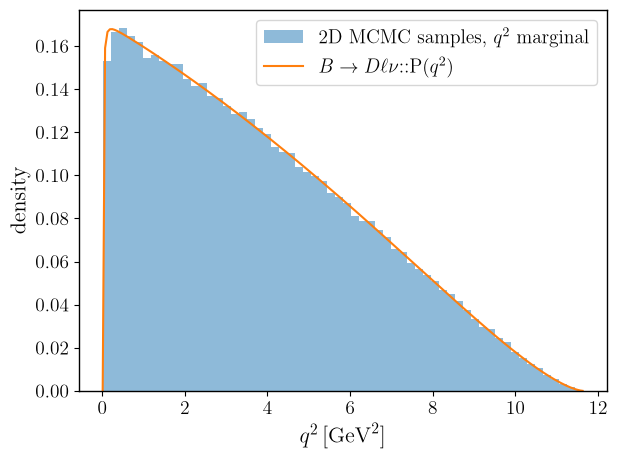

In [4]:
q2_kinematics = eos.Kinematics({'q2': 2.0, 'q2_min': Q2_PHYS_MIN, 'q2_max': Q2_PHYS_MAX})
q2_pdf = eos.SignalPDF.make('B->Dlnu::P(q2)', params, q2_kinematics, OPTIONS)

q2_grid  = np.linspace(Q2_PHYS_MIN, Q2_PHYS_MAX, 200)
q2_log_norm = q2_pdf.normalization()
q2_curve    = np.array([np.exp(q2_pdf.log_pdf([q2v]) - q2_log_norm) for q2v in q2_grid])

fig, ax = plt.subplots()
ax.hist(truth_samples[:, 0], bins=60, range=(Q2_PHYS_MIN, Q2_PHYS_MAX), density=True,
        alpha=0.5, label='2D MCMC samples, $q^2$ marginal')
ax.plot(q2_grid, q2_curve, color='C1', label=r'$B\to D\ell\nu$::P($q^2$)')
ax.set_xlabel(r'$q^2\,[\mathrm{GeV}^2]$')
ax.set_ylabel(r'density')
ax.legend()
fig.tight_layout()


## 2. A Gaussian detector resolution

We build a resolution over the *offsets* of $q^2$ and $\cos\theta_\ell$ as an EOS expression: a
Gaussian of width $\sigma_{q^2} = 0.3\,\mathrm{GeV}^2$ in the $q^2$ offset, and an effectively
vanishing width in the $\cos\theta_\ell$ offset, which realises "no smearing" as a numerical
Kronecker delta once sampled on the grid below. Both factors use the unit-area kernel
`Kernel::Gaussian(u, mu, sigma)`. The expression is handed directly to
[eos.DetectorLevelPDF.make_from_expression](../reference/python.rst#eos.DetectorLevelPDF.make_from_expression),
which samples it on the grid of offsets.

In [5]:
SIGMA_Q2 = 0.3    # GeV^2
EPS_COS  = 1.0e-3 # cos(theta_l): a width far below the grid spacing acts as a numerical delta

kernel_expr = (
    f'Kernel::Gaussian({{q2}}, 0, {SIGMA_Q2}) * '
    f'Kernel::Gaussian({{cos(theta_l)}}, 0, {EPS_COS})'
)

The convolution is circular, so the grid must extend well beyond the physical $q^2$ range on both
sides. Here we choose to pad by about $6\,\sigma_{q^2} \approx 1.8\,\mathrm{GeV}^2$ so that both the truth PDF and
the resolution are negligible at the wrap-around boundary. A reader adapting this example to a
different resolution width or a different decay should re-check this padding first: it is the most
common source of a silently wrong result. No such padding is needed for $\cos\theta_\ell$, since it
is not smeared and already spans its full physical range. The number of points per axis must be
even, per the requirements of the real discrete Fourier transform used internally.

In [6]:
AXES = [
    { 'variable': 'q2',           'min': -2.0, 'max': 13.6, 'points': 128 },
    { 'variable': 'cos(theta_l)', 'min': -1.0, 'max':  1.0, 'points': 16  },
]

# a dedicated cache: this DetectorLevelPDF is only used standalone in this notebook, not as part of
# an eos.LogLikelihood
cache = eos.ObservableCache(params)
detector_pdf = eos.DetectorLevelPDF.make_from_expression(cache, 'B->Dlnu::P(q2,cos(theta_l))', OPTIONS, AXES, kernel_expr)

# DetectorLevelPDF never updates the cache it was given; the owner of the cache does
cache.update()


## 3. Validating the convolution

We smear the step-1 $q^2$ samples by hand with the same Gaussian, and compare them against the $q^2$
marginal of `detector_pdf`. Since the resolution factorises into a $q^2$ Gaussian and a
$\cos\theta_\ell$ delta, this marginal equals the 1D convolution of the truth PDF's $q^2$ marginal
with the same Gaussian -- exactly what the hand-smeared samples estimate. We first check the marginal
numerically, by integrating `detector_pdf` over $\cos\theta_\ell$ and comparing against a quadrature
of the 1D convolution.

In [7]:
def detector_marginal_q2(pdf, q2_values, n_cos=41):
    """Marginalize a 2D detector-level PDF over cos(theta_l) by numerical integration.

    log_pdf() is evaluate(), i.e. the unnormalized log density, so the PDF's own log-normalization
    is subtracted to obtain a proper density -- exactly as for any other SignalPDF.
    """
    log_norm   = pdf.normalization()
    cos_values = np.linspace(-1.0, 1.0, n_cos)
    result = np.empty_like(q2_values)
    for i, q2v in enumerate(q2_values):
        density = np.array([np.exp(pdf.log_pdf([q2v, cv]) - log_norm) for cv in cos_values])
        result[i] = np.trapezoid(density, cos_values)
    return result


rng_smear  = np.random.mtrand.RandomState(90210)
q2_smeared = truth_samples[:, 0] + rng_smear.normal(0.0, SIGMA_Q2, size=truth_samples.shape[0])

hist_edges   = np.linspace(AXES[0]['min'], AXES[0]['max'], 61)
hist_centers = 0.5 * (hist_edges[:-1] + hist_edges[1:])

detector_curve = detector_marginal_q2(detector_pdf, hist_centers)

# the 1D convolution of the truth PDF's q2 marginal with the same Gaussian, by quadrature
q2_fine    = np.linspace(Q2_PHYS_MIN, Q2_PHYS_MAX, 400)
p1d_fine   = np.array([np.exp(q2_pdf.log_pdf([v]) - q2_log_norm) for v in q2_fine])
reference  = np.array([
    np.trapezoid(p1d_fine * np.exp(-0.5 * ((c - q2_fine) / SIGMA_Q2)**2) / (np.sqrt(2.0 * np.pi) * SIGMA_Q2), q2_fine)
    for c in hist_centers
])

deviation = np.abs(detector_curve - reference).max() / reference.max()
print(f'max deviation from the quadrature reference: {deviation:.2e}')
print(f'sample mean  q2: {q2_smeared.mean():.4f}   PDF: {np.trapezoid(hist_centers * reference, hist_centers) / np.trapezoid(reference, hist_centers):.4f}')


max deviation from the quadrature reference: 4.91e-03
sample mean  q2: 3.7852   PDF: 3.7877


We now plot the hand-smeared samples against a detector-level PDF using the EOS figure framework.
Plot items of type `detector-level-pdf` build an `eos.DetectorLevelPDF` from a truth-level PDF, a grid,
and a resolution expression, and plot it as a function of one of its variables, at fixed values of the
others. Here we use the 1D truth PDF `B->Dlnu::P(q2)` on the $q^2$ axis of the grid above, which
yields the $q^2$ marginal directly. The samples are first stored as an
[eos.data.ImportanceSamples](../reference/python.rst#eos.data.ImportanceSamples) object, so that a
`histogram1D` item can display them.

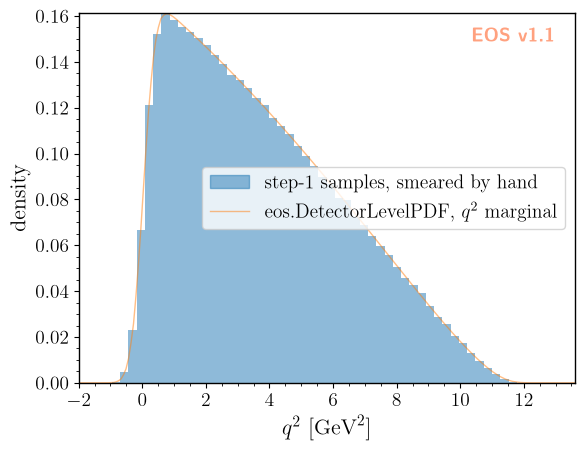

In [8]:
eos.data.ImportanceSamples.create(os.path.join(EOS_BASE_DIRECTORY, 'smeared', 'samples'), [truth_kinematics['q2']],
                                  q2_smeared.reshape(-1, 1), np.ones_like(q2_smeared))

Q2_AXIS = AXES[0]
figure_args = f'''
plot:
  xaxis: {{ label: '$q^2$', unit: '$\\textnormal{{GeV}}^2$', range: [{Q2_AXIS['min']}, {Q2_AXIS['max']}] }}
  yaxis: {{ label: 'density' }}
  legend: {{ position: 'center right' }}
  items:
    - {{ type: 'histogram1D', label: 'step-1 samples, smeared by hand', color: 'C0',
        variable: 'q2', bins: 60, range: [{Q2_AXIS['min']}, {Q2_AXIS['max']}],
        datafile: '{EOS_BASE_DIRECTORY}/smeared/samples'
      }}
    - {{ type: 'detector-level-pdf', label: 'eos.DetectorLevelPDF, $q^2$ marginal', color: 'C1',
        pdf: 'B->Dlnu::P(q2)', options: {{ l: 'mu', q: 'd', model: 'WET', form-factors: 'SSE' }},
        variable: 'q2', range: [{Q2_AXIS['min']}, {Q2_AXIS['max']}], resolution: 200,
        axes: [ {{ variable: 'q2', min: {Q2_AXIS['min']}, max: {Q2_AXIS['max']}, points: {Q2_AXIS['points']} }} ],
        kernel: 'Kernel::Gaussian({{q2}}, 0, {SIGMA_Q2})'
      }}
'''
figure = eos.figure.FigureFactory.from_yaml(figure_args)
figure.draw()

## 4. An unbinned fit

We now generate a set of $\sim 2000$ "observed" events by smearing a subsample of the step-1
truth-level samples, write them to an
[eos.data.UnbinnedLikelihood](../reference/python.rst#eos.data.UnbinnedLikelihood) data object
together with the (unnormalized) resolution kernel expression, and fit the form factor shape
parameters $\alpha^{f_+}_1$ and $\alpha^{f_+}_2$ in the "SSE" parametrization to them; we keep
$\alpha^{f_+}_0$, $V_{cb}$, and every other parameter fixed. The fit is driven through
[eos.AnalysisFile](../reference/python.rst#eos.AnalysisFile), reading `detector-level.yaml`, which
declares the `unbinned-B-to-D` likelihood component as `type: unbinned`.

In [9]:
# the standalone PDF is no longer needed; free its grid before the fit builds its own
del detector_pdf, cache

from eos.data.unbinned_likelihood import UnbinnedExpressionResolutionDescription

N_FIT = truth_samples.shape[0]
rng_fit = np.random.mtrand.RandomState(271828)

q2_obs  = truth_samples[:, 0] + rng_fit.normal(0.0, SIGMA_Q2, size=N_FIT)
cos_obs = truth_samples[:, 1]
observations = np.column_stack([q2_obs, cos_obs])

# the analysis file's relative 'data' path is resolved against the base directory passed to the
# tasks, so the data object must be written beneath it
eos.data.UnbinnedLikelihood.create(
    os.path.join(EOS_BASE_DIRECTORY, 'detector-level-data', 'observed-events'),
    axes=AXES,
    resolution=UnbinnedExpressionResolutionDescription(expression=kernel_expr),
    observations=observations,
)


Accordion(children=(Output(layout=Layout(height='200px', overflow='auto')),), titles=('data/FF-fit/mcmc-0000',…

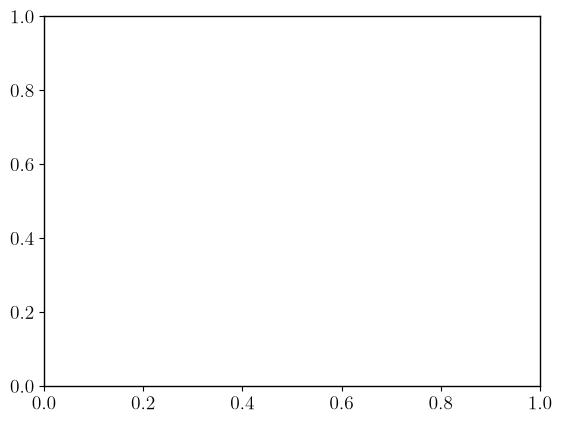

In [10]:
eos.tasks.sample_mcmc('detector-level.yaml', 'FF-fit', chain=0, base_directory=EOS_BASE_DIRECTORY,
                       pre_N=250, preruns=2, N=400, stride=3)


## 5. Closure

We compare the posterior mean and standard deviation of $\alpha^{f_+}_1$ and $\alpha^{f_+}_2$
against the values used to generate the samples in step 1, and report the pulls
$(\text{fit} - \text{true}) / \sigma_\text{fit}$.

The two parameters are not equally well determined. The unbinned likelihood constrains
$\alpha^{f_+}_1$ well: its posterior is some five times narrower than the uniform prior it was
given, so the agreement with the input value is a genuine closure test. $\alpha^{f_+}_2$, by
contrast, comes out essentially prior-limited — its posterior width is very close to the prior's.
That is physics rather than a shortcoming of the method: a $q^2$ spectrum smeared with
$\sigma_{q^2} = 0.3\,\textnormal{GeV}^2$ carries little information about the sub-leading shape
coefficient, and the log-likelihood varies by less than $0.1$ across the whole prior range for
$\alpha^{f_+}_2$. Read its histogram below as the prior, not as a measurement.

In [11]:
chain = eos.data.MarkovChain(os.path.join(EOS_BASE_DIRECTORY, 'data', 'FF-fit', 'mcmc-0000'))

alpha1_fit, alpha2_fit = np.mean(chain.samples, axis=0)
alpha1_std, alpha2_std = np.std(chain.samples, axis=0)

pull1 = (alpha1_fit - ALPHA1_TRUE) / alpha1_std
pull2 = (alpha2_fit - ALPHA2_TRUE) / alpha2_std

print(f'alpha^f+_1@SSE: true = {ALPHA1_TRUE:.4f}, fit = {alpha1_fit:.4f} +/- {alpha1_std:.4f}, pull = {pull1:+.2f}')
print(f'alpha^f+_2@SSE: true = {ALPHA2_TRUE:.4f}, fit = {alpha2_fit:.4f} +/- {alpha2_std:.4f}, pull = {pull2:+.2f}')


alpha^f+_1@SSE: true = -2.9843, fit = -2.9969 +/- 0.0459, pull = -0.28
alpha^f+_2@SSE: true = 3.8517, fit = 4.3732 +/- 0.8374, pull = +0.62


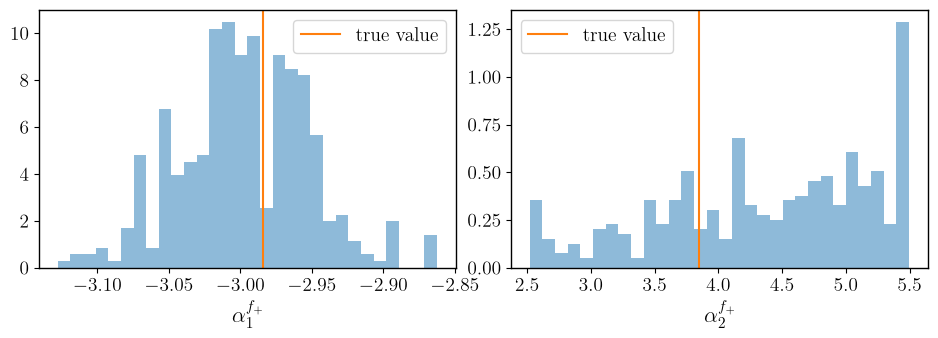

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ax, samples, true, name in zip(
    axes, chain.samples.T, (ALPHA1_TRUE, ALPHA2_TRUE), (r'$\alpha^{f_+}_1$', r'$\alpha^{f_+}_2$')
):
    ax.hist(samples, bins=30, density=True, alpha=0.5, color='C0')
    ax.axvline(true, color='C1', label='true value')
    ax.set_xlabel(name)
    ax.legend()
fig.tight_layout()


## 6. Plotting from the analysis file

Figures can also be declared in the analysis file, and drawn with the `draw-figure` task.
`detector-level.yaml` declares the figure `B-to-D-detector-level`. It shows the truth-level PDF and
the detector-level PDF at fixed $\cos\theta_\ell = 0$ as functions of $q^2$, at the parameter point
used to generate the events. Instead of an explicit grid and resolution, the `detector-level-pdf` item
refers to the data object of the fit through its `data` key, and reuses its grid and resolution.

Accordion(children=(Output(layout=Layout(height='200px', overflow='auto')),), titles=('figures',))

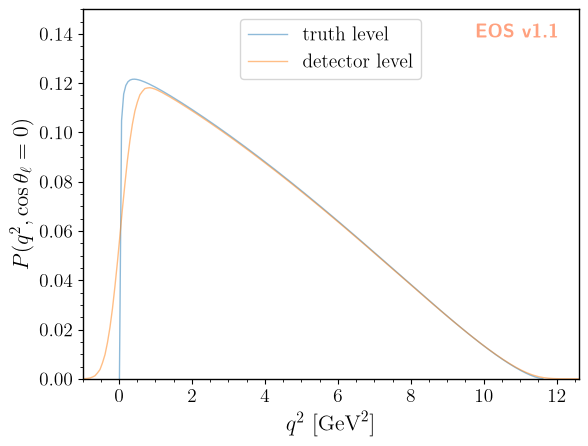

In [13]:
eos.tasks.draw_figure('detector-level.yaml', 'B-to-D-detector-level', base_directory=EOS_BASE_DIRECTORY)